#### 62 Hz, 70% vol., deployed fiber

## Required Libraries

In [2]:
import os
import gc
import numpy as np
import pandas as pd
import numexpr as ne
import matplotlib.pyplot as plt
from scipy import signal
from collections import deque
from scipy.signal import hilbert
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from scipy.signal import butter, filtfilt
from scipy.signal import welch
from scipy.interpolate import interp1d
from scipy.signal import butter, filtfilt, correlate, correlation_lags
import re


## Required Functions

In [3]:
def get_peaks(data, threshold, distance):
    # Convert data to a numpy array if it's not already
    data = np.asarray(data)
    # Find indices where data[i] is greater than its neighbors
    peaks = np.where((data[1:-1] > data[:-2]) & (data[1:-1] > data[2:]))[0] + 1
    # Apply threshold
    peaks = peaks[data[peaks] >= threshold]
    # Apply distance constraint
    if len(peaks) > 0:
        # Initialize the list of filtered peaks
        filtered_peaks = [peaks[0]]
        last_peak = peaks[0]
        for i in range(1, len(peaks)):
            if peaks[i] - last_peak >= distance:
                filtered_peaks.append(peaks[i])
                last_peak = peaks[i]
            elif data[peaks[i]] > data[last_peak]:
                # Replace the last peak with the current one if it's higher
                filtered_peaks[-1] = peaks[i]
                last_peak = peaks[i]   
        return filtered_peaks
    else:
        return []
    
def get_gaussian_filtered_fft(signal_fft, frequencies, band_width, freq_peak_index):
    # Find the peak frequency
    freq_peak = frequencies[freq_peak_index]
    
    # Create a Gaussian mask centered at the peak frequency
    # The Gaussian function is e^(-((f - f_peak)^2) / (2 * sigma^2))
    # Where sigma controls the width (band_width in this case)
    sigma = band_width / 2.355  # Convert band_width to standard deviation (band_width==FWHM to sigma)
    
    # Calculate the Gaussian mask for both positive and negative frequencies
    gaussian_mask = ne.evaluate("exp(-((frequencies - freq_peak)**2) / (2 * sigma**2))")
    gaussian_mask += ne.evaluate("exp(-((frequencies + freq_peak)**2) / (2 * sigma**2))")  # Symmetric for negative frequencies
    
    # Apply the Gaussian mask to the FFT of the signal
    filtered_fft_signal = signal_fft * gaussian_mask
    
    return filtered_fft_signal

## User Settings

In [4]:
fs = 1000       #Sampling frequency in Hz
c = 3e8         #Speed of light in m/s         
n_eff = 1.462   #Effective refractive indx of optical fiber
target_frequency = 62 #Hz
c_fiber = c / n_eff
x_expected = 15 
t_R = x_expected / c_fiber
t_L = 1000/c_fiber - t_R # total fiber length is 1000m

## Loading my excursion data in time series and plotting it.

Loading massive datasets using Pandas (this will be fast)...
Trimming data strictly to the specified time window...
----------------------------------------
Trimmed chunk: 5000s to 51136.744s
Corresponding Start String: '260630 201312.428'
Corresponding End String:   '260701 090208.476'
----------------------------------------
Extraction Complete! Loaded 46136745 samples. (768.95 minutes of data)


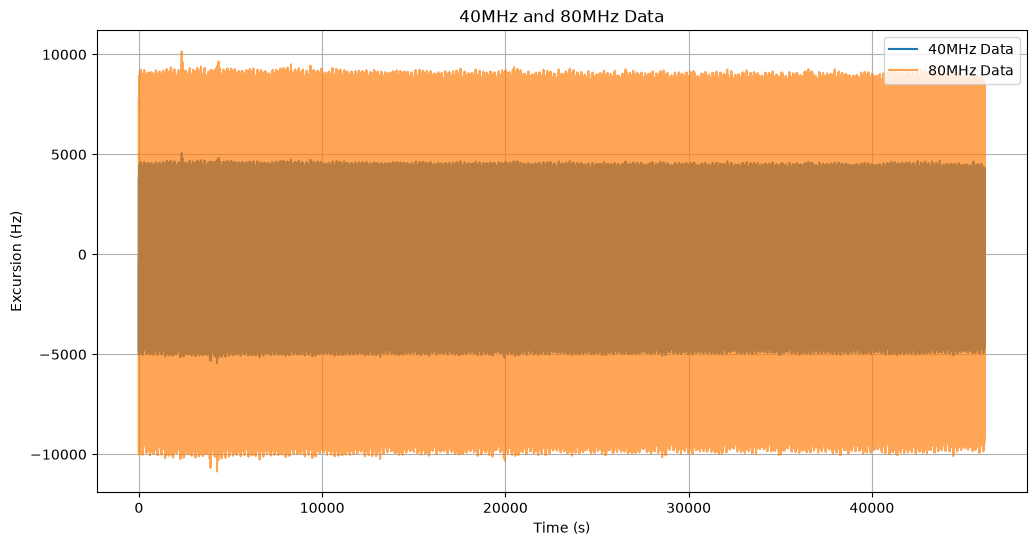

In [5]:
# --- 1. Configuration ---
# Provide a list of all files you want to seamlessly merge
filepaths = [
    r"D:\DAS_Ayan_newlaptop\DAS data distance amplitude\cone_infrontof_fiber\wrappedspeaker\deployed_fiber_data\Freq_A_5_260512_1.txt"
]

r'''
with open(filepaths[0], "r") as file:
    for i in range(20): # Change 20 to desired number of lines
        print(file.readline().strip())

with open(filepaths[0], "r") as file:
    # This keeps only the last 20 lines in memory
    last_lines = deque(file, maxlen=20) 

for line in last_lines:
    print(line.strip())
'''

# Set your desired trimming window
#start_time_str = '260701 224104.144'
#end_time_str   = '260702 090443.191'
fs = 1000  # Expected sampling frequency in Hz

#Set desired trimming window in relative seconds
start_sec = 5000
end_sec   = None

# --- 2. Fast Load & Merge using Pandas ---
print("Loading massive datasets using Pandas (this will be fast)...")
dfs = []

for filepath in filepaths:
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"File not found: {filepath}")
    
    # We load cols 0 (Date), 1 (Time), 3 (sig_40), and 4 (sig_80)
    df_temp = pd.read_csv(
    filepath, 
    sep=r'\s+', 
    usecols=[0, 1, 3, 4], 
    dtype={0: str, 1: str}, # <--- Forces Date and Time to be read as pure text
    header=None, 
    comment='#'
)
    dfs.append(df_temp)

# Concatenate all loaded files into one continuous DataFrame
df_data = pd.concat(dfs, ignore_index=True)

# --- 3. On-The-Spot Trimming ---
print("Trimming data strictly to the specified time window...")

# Ensure the time string is perfectly padded with leading zeros (e.g., "0.001" becomes "000000.001")
date_str = df_data.iloc[:, 0].astype(str)
time_str = df_data.iloc[:, 1].astype(str).str.zfill(10)

# Create temporary datetime series to do the math
datetimes = pd.to_datetime(
    date_str + ' ' + time_str, 
    format='%y%m%d %H%M%S.%f'
)

#start_dt = pd.to_datetime(start_time_str, format='%y%m%d %H%M%S.%f')
#end_dt   = pd.to_datetime(end_time_str, format='%y%m%d %H%M%S.%f')

# Apply the filter mask
#mask = (datetimes >= start_dt) & (datetimes <= end_dt)
#df_trimmed = df_data[mask]
#datetimes_trimmed = datetimes[mask]  # Keep this aligned for our frequency check

# Generate a relative time array for the whole dataset
t_relative = np.arange(len(df_data)) / fs

# ---> DYNAMIC END TIME CHECK <---
if end_sec is None:
    end_sec = t_relative[-1]  # Automatically sets to the last second of the file

# Apply the filter mask based on seconds instead of datetimes
mask = (t_relative >= start_sec) & (t_relative <= end_sec)

df_trimmed = df_data[mask]
datetimes_trimmed = datetimes[mask]
t_trimmed = t_relative[mask] # Keep original time axis for plotting

if df_trimmed.empty:
    raise ValueError("Trimmed dataset is empty! Please check if your start and end times match the file contents.")

# Automatically extract and print the corresponding strings for your reference
# .strftime formats the timestamp back to your exact format, slicing off the last 3 chars to match milliseconds
extracted_start_str = datetimes_trimmed.iloc[0].strftime('%y%m%d %H%M%S.%f')[:-3]
extracted_end_str   = datetimes_trimmed.iloc[-1].strftime('%y%m%d %H%M%S.%f')[:-3]

print("-" * 40)
print(f"Trimmed chunk: {start_sec}s to {end_sec}s")
print(f"Corresponding Start String: '{extracted_start_str}'")
print(f"Corresponding End String:   '{extracted_end_str}'")
print("-" * 40)

# --- 5. Extract Final Signals ---
# Since we dropped unneeded columns during load:
# df_trimmed.iloc[:, 2] is your 3:FXE_A3
# df_trimmed.iloc[:, 3] is your 4:FXE_A4
sig_40 = df_trimmed.iloc[:, 2].values.astype(float)
sig_80 = df_trimmed.iloc[:, 3].values.astype(float)
N = len(sig_40)

print(f"Extraction Complete! Loaded {N} samples. ({N / fs / 60:.2f} minutes of data)")

# Create a relative time array in seconds
dt = 1.0 / fs   #integration time 1ms                       
t_full = np.arange(len(sig_40)) * dt
sig_40 -= np.mean(sig_40)
sig_80 -= np.mean(sig_80)

plt.figure(figsize=(12, 6))
plt.plot(t_full[::100], sig_40[::100], label='40MHz Data')
plt.plot(t_full[::100], sig_80[::100], label='80MHz Data', alpha=0.7)
plt.title('40MHz and 80MHz Data')
plt.xlabel('Time (s)')
plt.ylabel('Excursion (Hz)')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


## Plotting the lab temperature and it's FFT over time

In [6]:
r'''
#start_time_str = '260630 203000.006'
#end_time_str   = '260701 090208.476'

# 1. Load the data
df = pd.read_csv(r"C:\Users\DAS\Desktop\DAS-Ayan\DAS data distance amplitude\cone_infrontof_fiber\weather_2026-07-01.csv")

# 2. Convert Timestamp column to datetime objects
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# 3. Filter data for the requested time range
pi_start_time = pd.to_datetime('2026-07-01 00:00:00')
pi_end_time = pd.to_datetime('2026-07-01 09:02:08')
filtered_df = df[(df['Timestamp'] >= pi_start_time) & (df['Timestamp'] <= pi_end_time)].copy()

# --- ORIGINAL TEMPERATURE PLOT ---

# considering the starting time as zero second
time_seconds = (filtered_df['Timestamp'] - filtered_df['Timestamp'].iloc[0]).dt.total_seconds()

plt.figure(figsize=(12,6))
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')
plt.title('Raspberry Pi Temperature Data (00:00 am - 09:02 am)')
plt.grid(True)
plt.tick_params(axis='x', rotation=45)
plt.plot(time_seconds, filtered_df['Temperature_C'], color='tab:red')
plt.tight_layout()
plt.show()

# --- NEW FFT ANALYSIS ---

# A. Calculate the sampling interval (dt) in seconds
# Using median to ignore occasional network/sensor jitters
time_deltas = filtered_df['Timestamp'].diff().dt.total_seconds().dropna()
dt = time_deltas.median()

# B. Extract temperature array and remove the DC offset (mean)
temp_data = filtered_df['Temperature_C'].values
temp_centered = temp_data - np.mean(temp_data)

# C. Apply FFT
# np.fft.rfft is used because our temperature data is purely real numbers
n = len(temp_centered)
fft_values = np.fft.rfft(temp_centered)
fft_freqs = np.fft.rfftfreq(n, d=dt)

# Calculate magnitude
fft_magnitude = np.abs(fft_values)

plt.figure(figsize=(12,6))
# D. Plot the FFT Spectrum
plt.plot(fft_freqs[1:], fft_magnitude[1:], color='tab:blue')
plt.ylabel('Magnitude')
plt.xlabel('Frequency (Hz)')
plt.title('Frequency Spectrum of Temperature Variations')
plt.xscale('log')
#ax2.set_yscale('log')
plt.grid(True)

# Temperature changes are usually very slow (low frequency).
# You may want to uncomment the line below to zoom in on the relevant low-frequency bands:
# ax2.set_xlim(0, 0.05) 

plt.tight_layout()
plt.show()

temp_max_mag = np.max(fft_magnitude)
temp_max_freq = fft_freqs[np.argmax(fft_magnitude)]
print("The maximum FFT magnitude is:", temp_max_mag)
print("The frequency of the maximum FFT magnitude is:", temp_max_freq, "Hz")
'''

'\n#start_time_str = \'260630 203000.006\'\n#end_time_str   = \'260701 090208.476\'\n\n# 1. Load the data\ndf = pd.read_csv(r"C:\\Users\\DAS\\Desktop\\DAS-Ayan\\DAS data distance amplitude\\cone_infrontof_fiber\\weather_2026-07-01.csv")\n\n# 2. Convert Timestamp column to datetime objects\ndf[\'Timestamp\'] = pd.to_datetime(df[\'Timestamp\'])\n\n# 3. Filter data for the requested time range\npi_start_time = pd.to_datetime(\'2026-07-01 00:00:00\')\npi_end_time = pd.to_datetime(\'2026-07-01 09:02:08\')\nfiltered_df = df[(df[\'Timestamp\'] >= pi_start_time) & (df[\'Timestamp\'] <= pi_end_time)].copy()\n\n# --- ORIGINAL TEMPERATURE PLOT ---\n\n# considering the starting time as zero second\ntime_seconds = (filtered_df[\'Timestamp\'] - filtered_df[\'Timestamp\'].iloc[0]).dt.total_seconds()\n\nplt.figure(figsize=(12,6))\nplt.xlabel(\'Time\')\nplt.ylabel(\'Temperature (°C)\')\nplt.title(\'Raspberry Pi Temperature Data (00:00 am - 09:02 am)\')\nplt.grid(True)\nplt.tick_params(axis=\'x\', rotat

The bin width of FFT =  0.000022 Hz


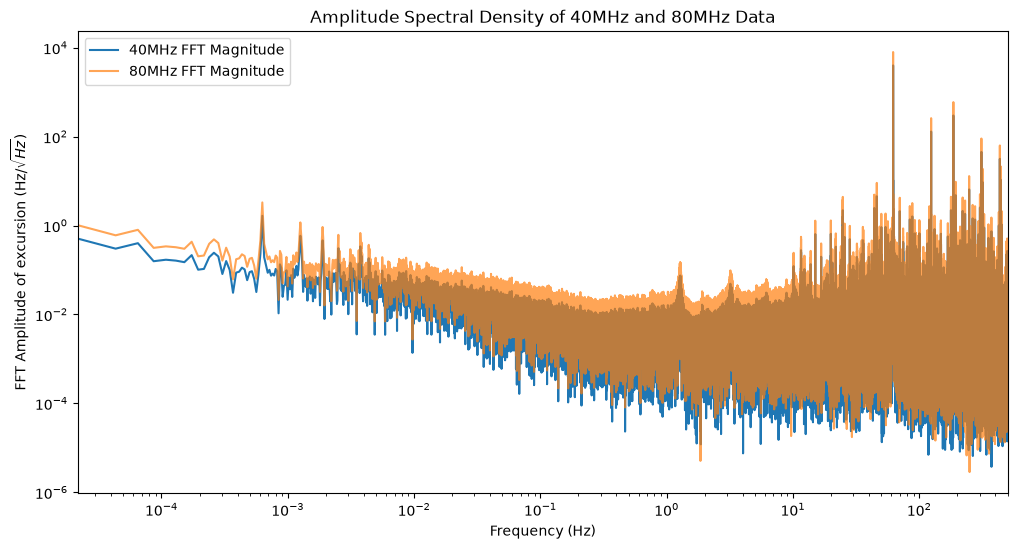

'\n#-----------------Portion of code to see FFT magnitude of signal at the frequency of max FFT amplitude obtained for temperature plot\n\n# 1. Define your target frequency from the previous analysis\ntarget_freq = temp_max_freq\n\n# 2. Find the index of the frequency bin that is closest to your target\n# We do this by subtracting the target from all frequencies, taking the absolute value, \n# and finding the index of the minimum difference.\nclosest_idx = np.argmin(np.abs(frequencies - target_freq))\n\n# 3. Look up the actual frequency of that bin and the corresponding magnitudes\nactual_bin_freq = frequencies[closest_idx]\ntarget_mag_40 = mag_40[closest_idx]\ntarget_mag_80 = mag_80[closest_idx]\n\nprint("-" * 40)\nprint(f"Target Frequency: {target_freq:.6f} Hz")\nprint(f"Closest FFT Bin Frequency: {actual_bin_freq:.6f} Hz")\nprint(f"Magnitude for 40MHz data: {target_mag_40}")\nprint(f"Magnitude for 80MHz data: {target_mag_80}")\nprint("-" * 40)\n\n#----------------Zooming in to see t

In [7]:
fft40 = np.fft.fft(sig_40)
fft80 = np.fft.fft(sig_80)
fs = 1000
dt = 1/fs
N = len(sig_40)
t_full = np.arange(N)*dt
N_t = len(t_full)
frequencies = np.fft.fftfreq(N_t, dt)
mag_40 = 2*np.abs(fft40)/N_t
mag_80 = 2*np.abs(fft80)/N_t
print("The bin width of FFT = ", f"{fs/N :.6f}", "Hz" )

plt.figure(figsize=(12,6))
# Fixed 'aqua' to 'alpha' and passed floats instead of strings
plt.plot(frequencies[1:N_t//2], mag_40[1:N_t//2], label='40MHz FFT Magnitude')
plt.plot(frequencies[1:N_t//2], mag_80[1:N_t//2], label='80MHz FFT Magnitude', alpha=0.7)
plt.title('Amplitude Spectral Density of 40MHz and 80MHz Data')
plt.xlabel('Frequency (Hz)')
plt.ylabel(r"FFT Amplitude of excursion (Hz/$\sqrt{Hz}$)") # Fixed curly braces
plt.xlim(frequencies[1], 500) # Limit x-axis to focus on relevant frequencies
plt.legend(loc='upper left')
plt.xscale('log')
plt.yscale('log')
plt.show()

r'''
#-----------------Portion of code to see FFT magnitude of signal at the frequency of max FFT amplitude obtained for temperature plot

# 1. Define your target frequency from the previous analysis
target_freq = temp_max_freq

# 2. Find the index of the frequency bin that is closest to your target
# We do this by subtracting the target from all frequencies, taking the absolute value, 
# and finding the index of the minimum difference.
closest_idx = np.argmin(np.abs(frequencies - target_freq))

# 3. Look up the actual frequency of that bin and the corresponding magnitudes
actual_bin_freq = frequencies[closest_idx]
target_mag_40 = mag_40[closest_idx]
target_mag_80 = mag_80[closest_idx]

print("-" * 40)
print(f"Target Frequency: {target_freq:.6f} Hz")
print(f"Closest FFT Bin Frequency: {actual_bin_freq:.6f} Hz")
print(f"Magnitude for 40MHz data: {target_mag_40}")
print(f"Magnitude for 80MHz data: {target_mag_80}")
print("-" * 40)

#----------------Zooming in to see temperature effect ---------------------

plt.figure(figsize=(12,6))
# Fixed 'aqua' to 'alpha' and passed floats instead of strings
plt.plot(frequencies[1:N_t//2], mag_40[1:N_t//2], label='40MHz FFT Magnitude')
plt.plot(frequencies[1:N_t//2], mag_80[1:N_t//2], label='80MHz FFT Magnitude', alpha=0.7)
plt.title('Amplitude Spectral Density of 40MHz and 80MHz Data')
plt.xlabel('Frequency (Hz)')
plt.ylabel(r"FFT Amplitude of excursion (Hz/$\sqrt{Hz}$)") # Fixed curly braces
plt.ylim(0,1.5)
plt.xlim(0.0001, 0.001) # Limit x-axis to focus on relevant frequencies
plt.legend(loc='upper left')
#plt.xscale('log')
#plt.yscale('log') 
plt.show()
'''


In [8]:
# 1. Find the actual maximum magnitude in your slightly-diluted data
actual_max_40 = np.max(mag_40[1:])
print(f"The absolute highest peak in the 40MHz data is: {actual_max_40:.2f}")

# 2. Set a new threshold dynamically to comfortably catch the peak (e.g., 60% of max)
new_threshold = actual_max_40 * 0.6

# 3. Define your desired peak separation in actual Hertz
desired_distance_hz = 2.0  # Require peaks to be at least 2 Hz apart

# 4. Calculate the bin width
bin_width = fs / N_t

# 5. Convert Hertz to integer bins
distance_in_bins = int(desired_distance_hz / bin_width)
print(f"Setting peak distance constraint to {distance_in_bins} bins ({desired_distance_hz} Hz)")

# 6. Use your dynamically calculated distance AND threshold
peak_indices = get_peaks(mag_40[:N_t//2], new_threshold, 0)

# Remove the [:N_t//2] slice, as mag_40 is already purely positive
#peak_indices = get_peaks(mag_40,30,10) # Threshold for excursion is set to 30 and minimum distance between peaks is set to 100Hz

print("Peak frequencies in 40MHz data:", frequencies[peak_indices])
print("Peak magnitudes in 40MHz data:", mag_40[peak_indices])
print("Peak frequencies in 80MHz data:", frequencies[peak_indices]) # We expect the same peaks in both
print("Peak magnitudes in 80MHz data:", mag_80[peak_indices])
print("Magnitude ratio (80MHz/40MHz) at peaks:", mag_80[peak_indices]/mag_40[peak_indices])

The absolute highest peak in the 40MHz data is: 4006.30
Setting peak distance constraint to 92273 bins (2.0 Hz)
Peak frequencies in 40MHz data: [62.00097124]
Peak magnitudes in 40MHz data: [4006.30009228]
Peak frequencies in 80MHz data: [62.00097124]
Peak magnitudes in 80MHz data: [8012.49165342]
Magnitude ratio (80MHz/40MHz) at peaks: [1.99997291]


In [9]:
#Set the target frequency you want to isolate
target_freq = 62

# Find the index of the frequency closest to 122.000 Hz
single_peak_index = np.argmin(np.abs(frequencies - target_freq))

# --- DISPLAY WHAT WAS PICKED ---
picked_freq = frequencies[single_peak_index]
picked_mag_40 = mag_40[single_peak_index]
picked_mag_80 = mag_80[single_peak_index]

print("--- Frequency Selection Info ---")
print(f"Targeting Index: {single_peak_index}")
print(f"Targeting Frequency: {picked_freq:.4f} Hz")
print(f"40MHz Magnitude: {picked_mag_40:.2f}")
print(f"80MHz Magnitude: {picked_mag_80:.2f}")
print(f"Magnitude Ratio (80/40): {picked_mag_80 / picked_mag_40:.4f}")
print("---------------------------")

# Inverse REAL FFT to get back to the time domain.
# We pass n=N_t to ensure the rebuilt signal is the exact same length as t
# full
filter40_122hz = get_gaussian_filtered_fft(fft40, frequencies, 1, single_peak_index)
filter80_122hz = get_gaussian_filtered_fft(fft80, frequencies, 1, single_peak_index)

# Delete the original FFT array since you no longer need it
del fft40
del fft80
gc.collect() # Force garbage collection

# Inverse FFT to get back to the time domain
amp40_122hz = np.fft.ifft(filter40_122hz).real
amp80_122hz = np.fft.ifft(filter80_122hz).real

--- Frequency Selection Info ---
Targeting Index: 2860478
Targeting Frequency: 62.0000 Hz
40MHz Magnitude: 29.27
80MHz Magnitude: 58.53
Magnitude Ratio (80/40): 2.0001
---------------------------


The bin width of FFT =  0.000022 Hz


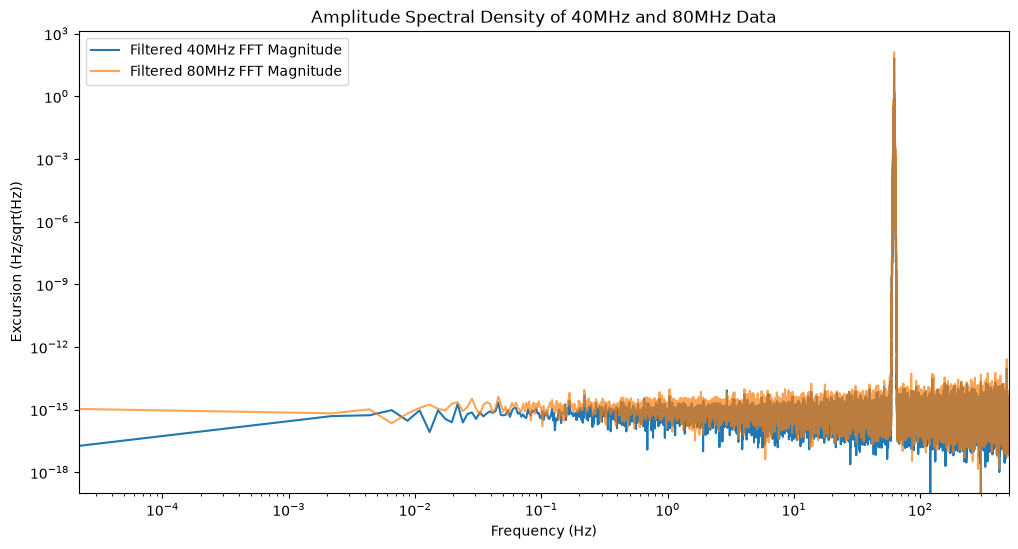

True FFT magnitude (40MHz): 4784.38
True FFT magnitude (80MHz): 9568.63
Magnitude ratio (80MHz/40MHz): 2.00


In [10]:
filtered_fft40 = np.fft.fft(amp40_122hz)
filtered_fft80 = np.fft.fft(amp80_122hz)
fs = 1000 # Sampling frequency in Hz
frequencies = np.fft.fftfreq(len(t_full), d=1/fs)
N_t = len(t_full)
filtered_mag40 = 2*np.abs(filtered_fft40)/N_t
filtered_mag80 = 2*np.abs(filtered_fft80)/N_t
print("The bin width of FFT = ", f"{fs/N_t :.6f}", "Hz" )

plt.figure(figsize=(12, 6))
# Because we used rfft, we no longer need to slice [1:N_t//2]. 
# The arrays already strictly contain only positive frequencies.
plt.plot(frequencies[1:N_t//2:100], filtered_mag40[1:N_t//2:100], label='Filtered 40MHz FFT Magnitude')
plt.plot(frequencies[1:N_t//2:100], filtered_mag80[1:N_t//2:100], label='Filtered 80MHz FFT Magnitude', alpha=0.7)
plt.title('Amplitude Spectral Density of 40MHz and 80MHz Data')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Excursion (Hz/sqrt(Hz))')
plt.xlim(frequencies[1], 500) # Limit x-axis to focus on relevant frequencies
plt.legend(loc='upper left')
plt.xscale('log')
plt.yscale('log')
plt.show()

true_mag_40_global = np.sqrt(np.sum(filtered_mag40[1:N_t//2]**2))
true_mag_80_global = np.sqrt(np.sum(filtered_mag80[1:N_t//2]**2))

print(f"True FFT magnitude (40MHz): {true_mag_40_global:.2f}")
print(f"True FFT magnitude (80MHz): {true_mag_80_global:.2f}")
print(f"Magnitude ratio (80MHz/40MHz): {true_mag_80_global/true_mag_40_global:.2f}")


#### Find Position

In [11]:
f_source = 62 #Hz
c_light = 3e8
n_eff = 1.462

complex40_122hz = hilbert(amp40_122hz)
complex80_122hz = hilbert(amp80_122hz)
#print(f"Complex values of signal 40: {complex40_122hz}")
#print(f"Complex values of signal 80: {complex80_122hz}")

# phase_diff = np.unwrap(np.angle(complex80_122hz)) - np.unwrap(np.angle(complex40_122hz))
phase_diff = np.unwrap(np.angle(complex40_122hz * np.conj(complex80_122hz)))
#print(f"Phase difference: {phase_diff} rad")
#print(f"Mean phase difference: {np.mean(phase_diff)} rad")
#print(f"Standard deviation of phase difference: {np.std(phase_diff)} rad")

x_measured = (phase_diff/(2 * np.pi * f_source * n_eff)) * c_light
x_mean = np.mean(x_measured)
x_std = np.std(x_measured)

print(f"Measured position of the source: {x_mean:.2f} m")
print(f"Standard deviation of the measured position: {x_std:.2f} m")


Measured position of the source: 929.75 m
Standard deviation of the measured position: 24.30 m


Processing raw data through full DSP pipeline in chunks...
Processed 1s chunks -> Std Dev: 28.1843 m
Processed 2s chunks -> Std Dev: 19.8404 m
Processed 4s chunks -> Std Dev: 14.0104 m
Processed 8s chunks -> Std Dev: 9.8629 m
Processed 16s chunks -> Std Dev: 7.0876 m
Processed 32s chunks -> Std Dev: 5.0562 m
Processed 64s chunks -> Std Dev: 3.6277 m
Processed 128s chunks -> Std Dev: 2.6485 m
Processed 256s chunks -> Std Dev: 1.9884 m
Processed 512s chunks -> Std Dev: 1.3712 m
Processed 1024s chunks -> Std Dev: 0.8741 m
Processed 2048s chunks -> Std Dev: 0.5526 m
Processed 4096s chunks -> Std Dev: 0.2979 m
Processed 8192s chunks -> Std Dev: 0.2293 m
Processed 16384s chunks -> Std Dev: 0.2325 m


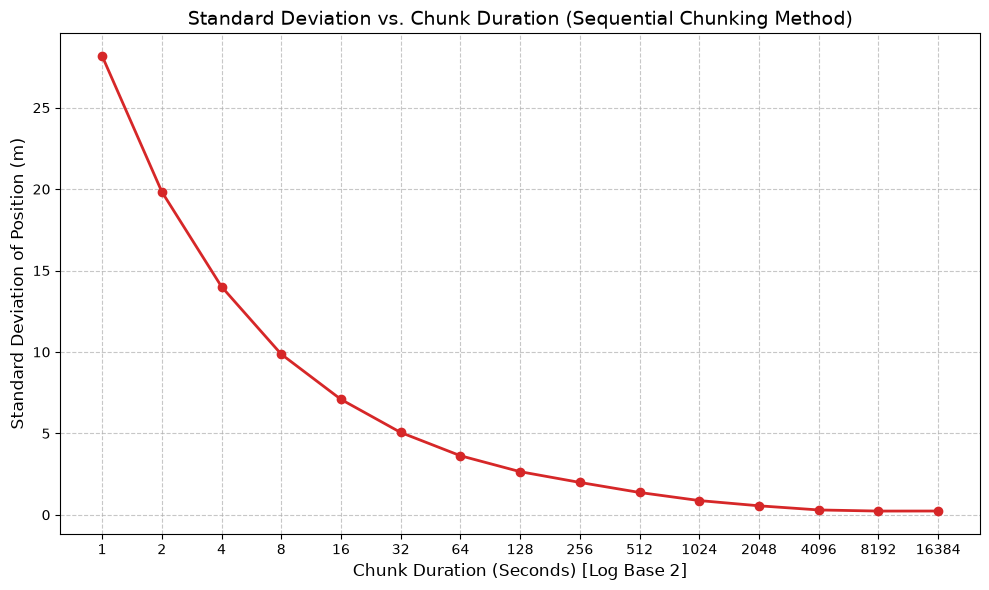

Saved sequential results to 'results_sequential_deployedfiber.npz'


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

# --- Assumed Pre-existing Variables ---
# sig_40, sig_80 : Your raw time-domain arrays
# fs             : 1000 (Sampling frequency)
# f_source       : 62 (Target frequency)
# c_light        : 3e8
# n_eff          : 1.462

# 1. Setup Chunking Variables
MIN_CHUNKS = 2 
total_samples = len(sig_40)
total_seconds = total_samples / fs

# Generate powers of 2 for chunk durations (1, 2, 4, 8, 16...)
max_power = int(np.floor(np.log2(total_seconds / MIN_CHUNKS)))
chunk_durations_sec = [2**i for i in range(max_power + 1)] 

std_of_means = []
mean_of_means = []
valid_durations = []

print("Processing raw data through full DSP pipeline in chunks...")

# 2. Main Processing Loop
for duration in chunk_durations_sec:
    chunk_size_samples = int(duration * fs)
    num_chunks = total_samples // chunk_size_samples
    
    if num_chunks < MIN_CHUNKS:
        break
        
    chunk_means = []
    
    # --- DYNAMIC FFT SETUP FOR THIS CHUNK SIZE ---
    # We must recalculate the frequency axis because N has changed
    frequencies = np.fft.fftfreq(chunk_size_samples, d=1/fs)
    
    # Find the bin closest to 62 Hz for this specific chunk length
    peak_idx = np.argmin(np.abs(frequencies - f_source))
    freq_peak = frequencies[peak_idx]
    
    # Pre-calculate the Gaussian mask for this chunk's frequency axis
    sigma = 1.0 / 2.355  # Bandwidth of 1 converted to sigma
    gaussian_mask = np.exp(-((frequencies - freq_peak)**2) / (2 * sigma**2))
    gaussian_mask += np.exp(-((frequencies + freq_peak)**2) / (2 * sigma**2))
    
    # --- PROCESS EACH CHUNK INDIVIDUALLY ---
    for i in range(num_chunks):
        # Slice the raw time-domain data
        start_idx = i * chunk_size_samples
        end_idx = start_idx + chunk_size_samples
        
        c_40 = sig_40[start_idx:end_idx]
        c_80 = sig_80[start_idx:end_idx]
        
        # Step A: FFT
        fft_40 = np.fft.fft(c_40)
        fft_80 = np.fft.fft(c_80)
        
        # Step B: Gaussian Filter
        filt_fft_40 = fft_40 * gaussian_mask
        filt_fft_80 = fft_80 * gaussian_mask
        
        # Step C: Inverse FFT
        amp40_filt = np.fft.ifft(filt_fft_40).real
        amp80_filt = np.fft.ifft(filt_fft_80).real
        
        # Step D: Hilbert Transform & Phase Extraction
        comp40 = hilbert(amp40_filt)
        comp80 = hilbert(amp80_filt)
        
        # Calculate phase difference
        phase_diff = np.unwrap(np.angle(comp40 * np.conj(comp80)))
        
        # Step E: Position Calculation
        x_meas = (phase_diff / (2 * np.pi * f_source * n_eff)) * c_light
        
        # Save the mean position for this specific chunk
        chunk_means.append(np.mean(x_meas))
        
    # --- CALCULATE STATISTICS FOR THIS DURATION ---
    # Standard deviation of the mean positions of all chunks
    current_std = np.std(chunk_means, ddof=1)
    current_mean = np.mean(chunk_means)
    
    std_of_means.append(current_std)
    mean_of_means.append(current_mean)
    valid_durations.append(duration)
    
    print(f"Processed {duration}s chunks -> Std Dev: {current_std:.4f} m")

# 3. Plotting the Results
plt.figure(figsize=(10, 6))
plt.plot(valid_durations, std_of_means, 'o-', linewidth=2, color='#d62728', markersize=6)

plt.title('Standard Deviation vs. Chunk Duration (Sequential Chunking Method)', fontsize=14)
plt.xlabel('Chunk Duration (Seconds) [Log Base 2]', fontsize=12)
plt.ylabel('Standard Deviation of Position (m)', fontsize=12)

# Format X-axis to show powers of 2 clearly
plt.xscale('log', base=2)
import matplotlib.ticker as ticker
ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.ScalarFormatter()) 
plt.xticks(valid_durations, valid_durations) 

plt.grid(True, which="major", ls="--", alpha=0.7)
plt.grid(True, which="minor", ls=":", alpha=0.4)
plt.tight_layout()
plt.show()

# ... (rest of your sequential processing code) ...

# Save the results to a file instead of plotting
np.savez('results_sequential_deployedfiber.npz', 
         durations=valid_durations, 
         std_devs=std_of_means,
         all_chunk_means=mean_of_means)

print("Saved sequential results to 'results_sequential_deployedfiber.npz'")

#### Applying $\chi^{2}$ statistics to choose optimal chunk duration for sequential chunking


--- Running Statistical Cutoff Analysis ---

Number of chunks considered for each duration:
  Duration: 1s -> Chunks: 46136
  Duration: 2s -> Chunks: 23068
  Duration: 4s -> Chunks: 11534
  Duration: 8s -> Chunks: 5767
  Duration: 16s -> Chunks: 2883
  Duration: 32s -> Chunks: 1441
  Duration: 64s -> Chunks: 720
  Duration: 128s -> Chunks: 360
  Duration: 256s -> Chunks: 180
  Duration: 512s -> Chunks: 90
  Duration: 1024s -> Chunks: 45
  Duration: 2048s -> Chunks: 22
  Duration: 4096s -> Chunks: 11
  Duration: 8192s -> Chunks: 5
  Duration: 16384s -> Chunks: 2
---------------------------------------------

Tolerance Limit Set: 1.5x
Optimal Maximum Chunk Duration: 2048 seconds


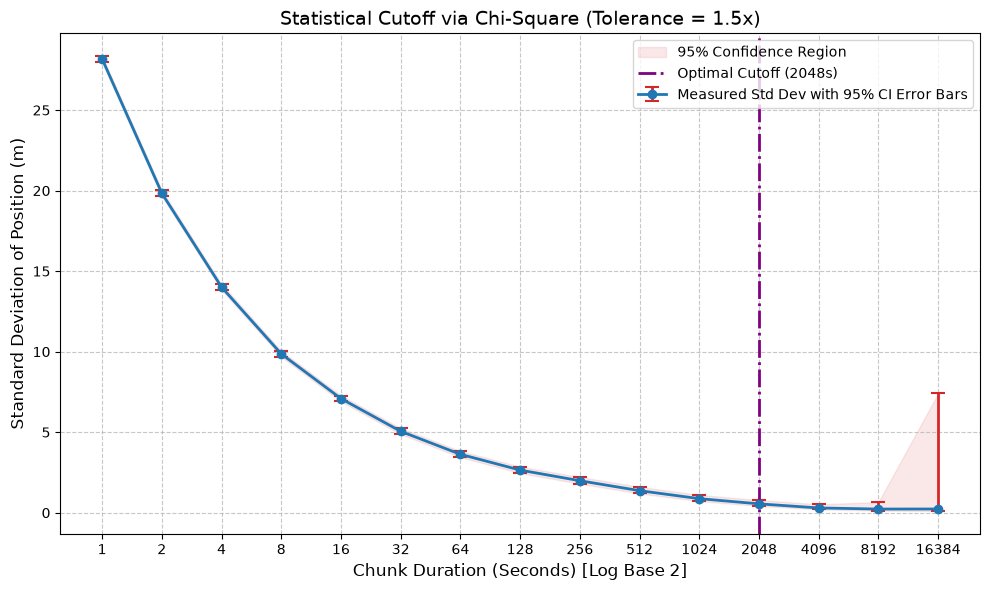


Saved Chi-Square bounds to 'results_chisquare_deployedfiber.npz'


In [16]:
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

print("\n--- Running Statistical Cutoff Analysis ---")

TOLERANCE_LIMIT = 1.50

valid_durations_arr = np.array(valid_durations)
std_of_means_arr = np.array(std_of_means)

N_chunks = np.floor(total_seconds / valid_durations_arr).astype(int)

# --- NEW: Print the number of chunks for each duration ---
print("\nNumber of chunks considered for each duration:")
for duration, chunks in zip(valid_durations_arr, N_chunks):
    print(f"  Duration: {duration}s -> Chunks: {chunks}")
print("-" * 45 + "\n")
# ---------------------------------------------------------

df = N_chunks - 1

chi2_025 = stats.chi2.ppf(0.025, df)
chi2_0975 = stats.chi2.ppf(0.975, df)

upper_ratios = np.sqrt(df / chi2_025)
lower_ratios = np.sqrt(df / chi2_0975)

upper_bounds = std_of_means_arr * upper_ratios
lower_bounds = std_of_means_arr * lower_ratios

acceptable_indices = np.where(upper_ratios <= TOLERANCE_LIMIT)[0]

if len(acceptable_indices) > 0:
    optimal_idx = acceptable_indices[-1]
    optimal_duration = valid_durations_arr[optimal_idx]
    print(f"Tolerance Limit Set: {TOLERANCE_LIMIT}x")
    print(f"Optimal Maximum Chunk Duration: {optimal_duration} seconds")
    save_optimal_duration = optimal_duration 
else:
    print(f"Warning: No chunk durations met the tolerance limit of {TOLERANCE_LIMIT}x.")
    optimal_duration = None
    save_optimal_duration = -1.0 

# --- PLOT & SAVE CHI-SQUARE RESULTS ---
yerr_lower = std_of_means_arr - lower_bounds
yerr_upper = upper_bounds - std_of_means_arr
y_errors = [yerr_lower, yerr_upper]

plt.figure(figsize=(10, 6))
plt.errorbar(valid_durations_arr, std_of_means_arr, yerr=y_errors, fmt='o-', 
             linewidth=2, color='#1f77b4', ecolor='#d62728', capsize=5, capthick=1.5,
             label='Measured Std Dev with 95% CI Error Bars')
plt.fill_between(valid_durations_arr, lower_bounds, upper_bounds, color='#d62728', alpha=0.1, label='95% Confidence Region')

if optimal_duration is not None:
    plt.axvline(x=optimal_duration, color='purple', linestyle='-.', linewidth=2, label=f'Optimal Cutoff ({optimal_duration}s)')

plt.title(f'Statistical Cutoff via Chi-Square (Tolerance = {TOLERANCE_LIMIT}x)', fontsize=14)
plt.xlabel('Chunk Duration (Seconds) [Log Base 2]', fontsize=12)
plt.ylabel('Standard Deviation of Position (m)', fontsize=12)
plt.xscale('log', base=2)
ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.ScalarFormatter()) 
plt.xticks(valid_durations_arr, valid_durations_arr) 
plt.grid(True, which="major", ls="--", alpha=0.7)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

np.savez('results_chisquare_deployedfiber.npz', 
         chi2_upper=upper_bounds,          
         chi2_lower=lower_bounds,          
         optimal_duration=np.array([save_optimal_duration])) 
print("\nSaved Chi-Square bounds to 'results_chisquare_deployedfiber.npz'")

#### chunking process with overlapping chunks

Processing raw data through full DSP pipeline in chunks...
Processed 1s chunks -> Std Dev: 34.3760 m
Processed 2s chunks -> Std Dev: 23.2060 m
Processed 4s chunks -> Std Dev: 15.1013 m
Processed 8s chunks -> Std Dev: 10.2955 m
Processed 16s chunks -> Std Dev: 7.2514 m
Processed 32s chunks -> Std Dev: 5.1321 m
Processed 64s chunks -> Std Dev: 3.7071 m
Processed 128s chunks -> Std Dev: 2.6667 m
Processed 256s chunks -> Std Dev: 1.9491 m
Processed 512s chunks -> Std Dev: 1.3738 m
Processed 1024s chunks -> Std Dev: 0.8633 m
Processed 2048s chunks -> Std Dev: 0.5241 m
Processed 4096s chunks -> Std Dev: 0.3190 m
Processed 8192s chunks -> Std Dev: 0.1779 m
Processed 16384s chunks -> Std Dev: 0.1495 m


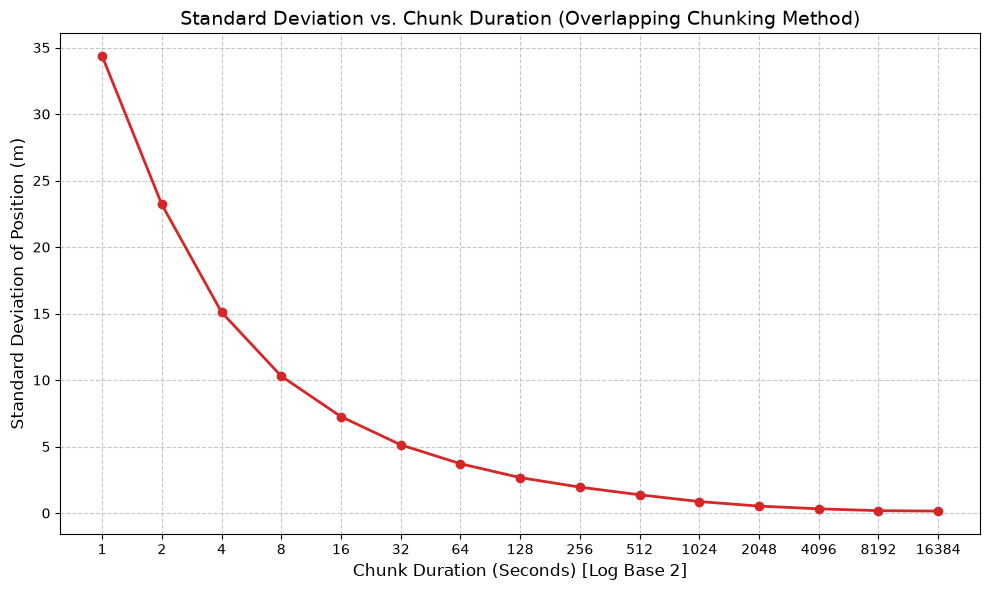

Saved overlapping results to 'results_overlapping_deployedfiber.npz'


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

# --- Assumed Pre-existing Variables ---
# sig_40, sig_80 : Your raw time-domain arrays
# fs             : 1000 (Sampling frequency)
# f_source       : 62 (Target frequency)
# c_light        : 3e8
# n_eff          : 1.462

# 1. Setup Chunking Variables
MIN_CHUNKS = 2 
total_samples = len(sig_40)
total_seconds = total_samples / fs

# Generate powers of 2 for chunk durations (1, 2, 4, 8, 16...)
max_power = int(np.floor(np.log2(total_seconds / MIN_CHUNKS)))
chunk_durations_sec = [2**i for i in range(max_power + 1)] 

std_of_means = []
mean_of_means = []
valid_durations = []

overlap_fraction = 0.5 # 50 % overlapping of chunks  

print("Processing raw data through full DSP pipeline in chunks...")

# 2. Main Processing Loop
for duration in chunk_durations_sec:
    chunk_size_samples = int(duration * fs)
    num_chunks = total_samples // chunk_size_samples
    
    if num_chunks < MIN_CHUNKS:
        break
        
    chunk_means = []
    
    # --- DYNAMIC FFT SETUP FOR THIS CHUNK SIZE ---
    # We must recalculate the frequency axis because N has changed
    frequencies = np.fft.fftfreq(chunk_size_samples, d=1/fs)
    
    # Find the bin closest to 62 Hz for this specific chunk length
    peak_idx = np.argmin(np.abs(frequencies - f_source))
    freq_peak = frequencies[peak_idx]
    
    # Pre-calculate the Gaussian mask for this chunk's frequency axis
    sigma = 1.0 / 2.355  # Bandwidth of 1 converted to sigma
    gaussian_mask = np.exp(-((frequencies - freq_peak)**2) / (2 * sigma**2))
    gaussian_mask += np.exp(-((frequencies + freq_peak)**2) / (2 * sigma**2))

    # Selecting the step size for overlapping chunks
    step_size = int(chunk_size_samples * (1 - overlap_fraction)) 

    # Pre-generate the window for this specific chunk size to save CPU cycles
    window = np.hanning(chunk_size_samples)
    
    # --- PROCESS EACH CHUNK INDIVIDUALLY ---
    for start_idx in range(0, total_samples - chunk_size_samples + 1, step_size):
        # Slice the raw time-domain data
        end_idx = start_idx + chunk_size_samples
        
        c_40 = sig_40[start_idx:end_idx]
        c_80 = sig_80[start_idx:end_idx]
        
        # --- CORRECTION 2: APPLY HANN WINDOW ---
        window = np.hanning(chunk_size_samples)
        c_40_windowed = c_40 * window
        c_80_windowed = c_80 * window
        
        # Step A: FFT (Using windowed data)
        fft_40 = np.fft.fft(c_40_windowed)
        fft_80 = np.fft.fft(c_80_windowed)
        
        # Step B: Gaussian Filter
        filt_fft_40 = fft_40 * gaussian_mask
        filt_fft_80 = fft_80 * gaussian_mask
        
        # Step C: Inverse FFT
        amp40_filt = np.fft.ifft(filt_fft_40).real
        amp80_filt = np.fft.ifft(filt_fft_80).real
        
        # --- CORRECTION 3: SCALE FOR WINDOW LOSS ---
        amp40_filt = amp40_filt * 2.0
        amp80_filt = amp80_filt * 2.0
        
        # Step D: Hilbert Transform
        comp40 = hilbert(amp40_filt)
        comp80 = hilbert(amp80_filt)
        
        # Calculate phase difference
        phase_diff = np.unwrap(np.angle(comp40 * np.conj(comp80)))
        
        # Step E: Position Calculation
        x_meas = (phase_diff / (2 * np.pi * f_source * n_eff)) * c_light
        
        # Save the mean position for this specific chunk
        chunk_means.append(np.mean(x_meas))
        
    # --- CALCULATE STATISTICS FOR THIS DURATION ---
    # Standard deviation of the mean positions of all chunks
    current_std = np.std(chunk_means, ddof=1)
    current_mean = np.mean(chunk_means) 
    
    std_of_means.append(current_std)
    mean_of_means.append(current_mean)
    valid_durations.append(duration)
    
    print(f"Processed {duration}s chunks -> Std Dev: {current_std:.4f} m")

# 3. Plotting the Results
plt.figure(figsize=(10, 6))
plt.plot(valid_durations, std_of_means, 'o-', linewidth=2, color='#d62728', markersize=6)

plt.title('Standard Deviation vs. Chunk Duration (Overlapping Chunking Method)', fontsize=14)
plt.xlabel('Chunk Duration (Seconds) [Log Base 2]', fontsize=12)
plt.ylabel('Standard Deviation of Position (m)', fontsize=12)

# Format X-axis to show powers of 2 clearly
plt.xscale('log', base=2)
import matplotlib.ticker as ticker
ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.ScalarFormatter()) 
plt.xticks(valid_durations, valid_durations) 

plt.grid(True, which="major", ls="--", alpha=0.7)
plt.grid(True, which="minor", ls=":", alpha=0.4)
plt.tight_layout()
plt.show()

# ... (rest of your overlapping processing code) ...

# Save the results to a file instead of plotting
np.savez('results_overlapping_deployedfiber.npz', 
         durations=valid_durations, 
         std_devs=std_of_means,
         all_chunk_means=mean_of_means)
print("Saved overlapping results to 'results_overlapping_deployedfiber.npz'")

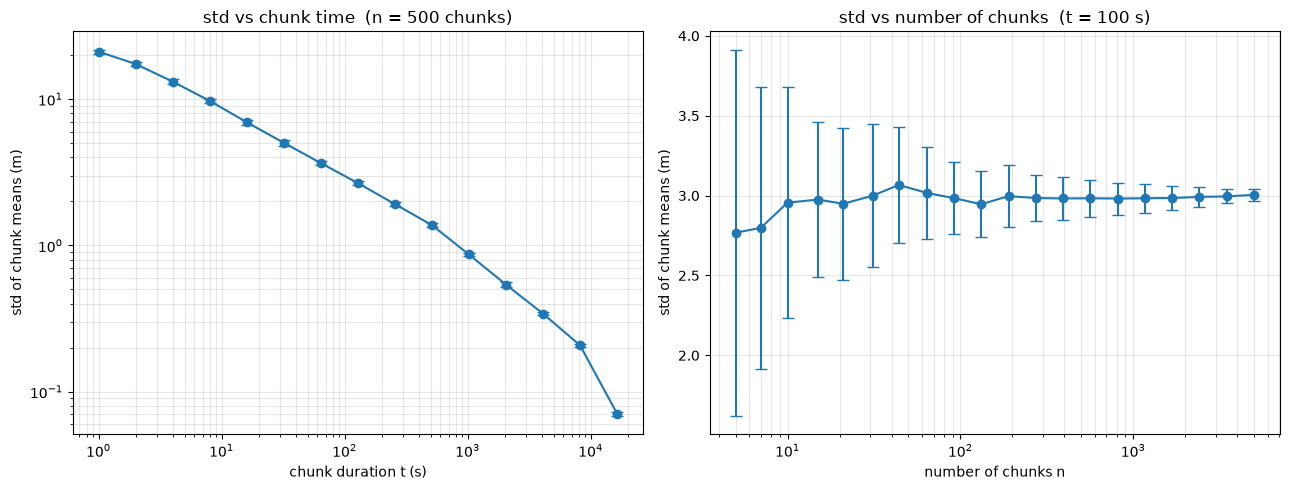

t =        1 s   std =    21.14
t =        2 s   std =    17.40
t =        4 s   std =    13.19
t =        8 s   std =     9.74
t =       16 s   std =     6.96
t =       32 s   std =     5.03
t =       64 s   std =     3.66
t =      128 s   std =     2.67
t =      256 s   std =     1.92
t =      512 s   std =     1.38
t =     1024 s   std =     0.87
t =     2048 s   std =     0.54
t =     4096 s   std =     0.34
t =     8192 s   std =     0.21
t =    16384 s   std =     0.07
Saved random chunking results to 'results_random_deployedfiber.npz'


In [ ]:
# --- How does the std of the position estimate depend on chunk time and on n_chunks? ---
# Sweep 1: fix n_chunks, vary the chunk duration t.
# Sweep 2: fix t, vary the number of random chunks n.
# In both cases each chunk starts at a random position anywhere in the record.

fs = 1000
x  = np.asarray(x_measured, float)

# Prefix sums let us get any chunk's mean in O(1): mean(x[s:s+cs]) = (c[s+cs]-c[s])/cs.
# Centering before the cumsum keeps float64 rounding negligible over ~1e7 samples.
x_off = x.mean()
c = np.concatenate(([0.0], np.cumsum(x - x_off)))

def chunk_std(chunk_t, n_chunks, rng):
    """Mean and std of n_chunks random chunks of duration chunk_t seconds."""
    cs = int(chunk_t * fs)
    max_start = len(x) - cs
    if cs < 1 or max_start < 0:
        return np.nan, np.nan
    s = rng.integers(0, max_start + 1, size=n_chunks)
    means = (c[s + cs] - c[s]) / cs + x_off
    return means.mean(), means.std(ddof=1)

n_repeats = 20          # redraw each point this many times to show estimator scatter
T_max = len(x) / fs / 2 # keep chunks well shorter than the record

# ---- Sweep 1: std vs chunk time ----
n_fixed = 500
times = 2.0**np.arange(0, int(np.floor(np.log2(T_max))) + 1)  # 1, 2, 4, ... up to T_max
sd_t = np.array([[chunk_std(t, n_fixed, np.random.default_rng(r))[1]
                  for r in range(n_repeats)] for t in times])

# --- ADD THIS NEW ARRAY TO EXTRACT THE MEANS ---
mean_t = np.array([[chunk_std(t, n_fixed, np.random.default_rng(r))[0] 
                    for r in range(n_repeats)] for t in times])

# ---- Sweep 2: std vs number of chunks ----
t_fixed = 100.0
ns = np.unique(np.round(np.logspace(np.log10(5), np.log10(5000), 20))).astype(int)
sd_n = np.array([[chunk_std(t_fixed, int(n), np.random.default_rng(r))[1]
                  for r in range(n_repeats)] for n in ns])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].errorbar(times, sd_t.mean(1), yerr=sd_t.std(1), fmt='o-', capsize=4)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('chunk duration t (s)'); ax[0].set_ylabel('std of chunk means (m)')
ax[0].set_title(f'std vs chunk time  (n = {n_fixed} chunks)')
ax[0].grid(True, which='both', alpha=0.3)

ax[1].errorbar(ns, sd_n.mean(1), yerr=sd_n.std(1), fmt='o-', capsize=4)
ax[1].set_xscale('log')
ax[1].set_xlabel('number of chunks n'); ax[1].set_ylabel('std of chunk means (m)')
ax[1].set_title(f'std vs number of chunks  (t = {t_fixed:.0f} s)')
ax[1].grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

for t, row in zip(times, sd_t):
    print(f"t = {t:8.0f} s   std = {row.mean():8.2f}")

# ... (rest of your random chunking code up to sd_n calculation) ...

# Save Sweep 1 (Chunk Time vs Std) to a file
np.savez('results_random_deployedfiber.npz', 
         durations=times, 
         std_devs=sd_t.mean(1),
         std_errs=sd_t.std(1),
         all_chunk_means=mean_t.mean(1)) # <--- ADD THIS

print("Saved random chunking results to 'results_random_deployedfiber.npz'")

#### Find the chunck duration for minimum standard deviation

Scanning chunk sizes using exact Chi-Square bounds...

--- SCIENTIFIC CONCLUSION ---
Optimized Chunk Window: 4096 seconds
Standard Deviation: 0.2986 meters
Mathematical Basis: Algorithm automatically halted at the Chi-Square structural limit (Upper bound diverged).


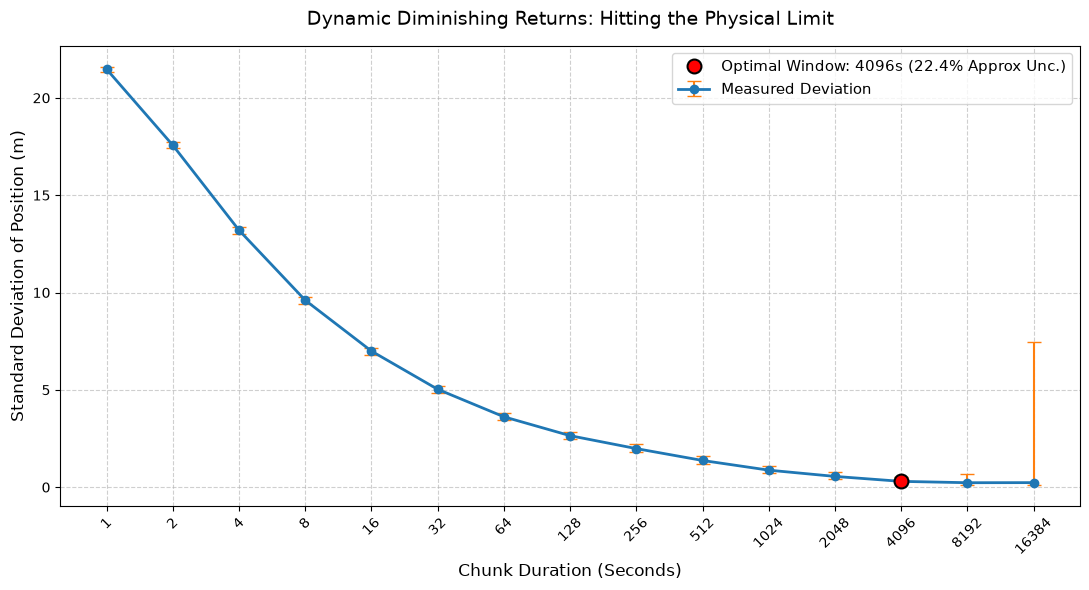

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.signal import hilbert
from scipy.stats import chi2

# --- Assuming amp40_122hz, amp80_122hz, fs, f_source, n_eff, c_light are already defined ---
f_source = 62
c_light = 3e8

# -----------------------------------------------------------------
# 1. CALCULATE GLOBAL PHASE & POSITION
# -----------------------------------------------------------------
complex40_global = hilbert(amp40_122hz)
complex80_global = hilbert(amp80_122hz)

phase_diff_global = np.unwrap(np.angle(complex40_global * np.conj(complex80_global)))
x_measured_global = (phase_diff_global / (2 * np.pi * f_source * n_eff)) * c_light

# -----------------------------------------------------------------
# 2. SETUP DYNAMIC CHUNKING
# -----------------------------------------------------------------
MIN_CHUNKS = 2 
total_seconds = len(x_measured_global) / fs
max_chunk_sec = total_seconds / MIN_CHUNKS
max_power = int(np.floor(np.log2(max_chunk_sec)))
chunk_durations_sec = [2**i for i in range(max_power + 1)] 

# -----------------------------------------------------------------
# 3. CALCULATE STANDARD DEVIATION & EXACT CHI-SQUARE BOUNDS
# -----------------------------------------------------------------
print("Scanning chunk sizes using exact Chi-Square bounds...")

std_of_means = []
valid_durations = []
upper_bounds = []
lower_bounds = []
pct_uncertainties = [] # Kept purely for the text labels

for duration in chunk_durations_sec:
    chunk_size_samples = int(duration * fs)
    num_chunks = len(x_measured_global) // chunk_size_samples
    
    if num_chunks < MIN_CHUNKS:
        break
        
    valid_length = num_chunks * chunk_size_samples
    x_trunc = x_measured_global[:valid_length]
    
    x_chunks = x_trunc.reshape(num_chunks, chunk_size_samples)
    chunk_means = np.mean(x_chunks, axis=1)
    
    current_std = np.std(chunk_means, ddof=1)
    df = num_chunks - 1  # Degrees of freedom
    
    # Calculate exact 95% Confidence Interval using Chi-Square distribution (NIST SP 1065)
    lower_bound_std = current_std * np.sqrt(df / chi2.ppf(0.975, df))
    upper_bound_std = current_std * np.sqrt(df / chi2.ppf(0.025, df))
    
    # Store legacy percentage for the legend text
    pct_uncertainty = (1.0 / np.sqrt(2 * df)) * 100
    
    std_of_means.append(current_std)
    lower_bounds.append(lower_bound_std)
    upper_bounds.append(upper_bound_std)
    pct_uncertainties.append(pct_uncertainty)
    valid_durations.append(duration)

# Convert all to numpy arrays
valid_durations = np.array(valid_durations)
std_of_means = np.array(std_of_means)
lower_bounds = np.array(lower_bounds)
upper_bounds = np.array(upper_bounds)
pct_uncertainties = np.array(pct_uncertainties)

# -----------------------------------------------------------------
# 4. ASYMPTOTE DETECTION (Universal Global Minimum Approach)
# -----------------------------------------------------------------
# When df is small, the upper bound explodes, causing massive asymmetry.
upper_error_margin = upper_bounds - std_of_means
lower_error_margin = std_of_means - lower_bounds
asymmetry_ratio = upper_error_margin / lower_error_margin

# 1. Enforce strict statistical validity (Chi-Square limit)
ASYMMETRY_LIMIT = 3.0 
statistically_valid_indices = np.where(asymmetry_ratio < ASYMMETRY_LIMIT)[0]

if len(statistically_valid_indices) == 0:
    optimal_idx = 0
    reason = "Data size too small to establish statistical validity."
else:
    # 2. Find the absolute lowest standard deviation in the valid region
    valid_stds = std_of_means[statistically_valid_indices]
    absolute_min_std = np.min(valid_stds)
    
    # 3. Apply the 15% rule to the GLOBAL minimum, not the local step.
    # We define diminishing returns as getting within 15% of the absolute best valid value.
    tolerance_threshold = absolute_min_std * 1.15 
    
    # Find the earliest valid index that achieves this precision
    optimal_valid_pos = np.where(valid_stds <= tolerance_threshold)[0][0]
    optimal_idx = statistically_valid_indices[optimal_valid_pos]
    
    # 4. Determine the mathematical basis for reporting
    if optimal_idx == statistically_valid_indices[-1]:
        reason = "Algorithm automatically halted at the Chi-Square structural limit (Upper bound diverged)."
    else:
        reason = "Physical noise floor reached (within 15% of absolute valid minimum)."

optimal_time = valid_durations[optimal_idx]
optimal_std = std_of_means[optimal_idx]
optimal_pct_err = pct_uncertainties[optimal_idx]

print("\n--- SCIENTIFIC CONCLUSION ---")
print(f"Optimized Chunk Window: {optimal_time} seconds")
print(f"Standard Deviation: {optimal_std:.4f} meters")
print(f"Mathematical Basis: {reason}")

# -----------------------------------------------------------------
# 5. PLOT THE RESULTS (With Asymmetric Chi-Square Error Bars)
# -----------------------------------------------------------------
plt.figure(figsize=(11, 6))

# Matplotlib accepts a 2xN array for asymmetric error bars: [lower_errors, upper_errors]
asymmetric_yerr = [lower_error_margin, upper_error_margin]

# Plot data
plt.errorbar(valid_durations, std_of_means, yerr=asymmetric_yerr, 
             fmt='o-', linewidth=2, color='#1f77b4', ecolor='#ff7f0e', 
             capsize=5, elinewidth=1.5, label='Measured Deviation')

# Highlight the optimized mark
plt.plot(optimal_time, optimal_std, 'ro', markersize=10, mec='black', mew=1.5, zorder=5,
         label=f'Optimal Window: {optimal_time}s ({optimal_pct_err:.1f}% Approx Unc.)')

# Titles and Labels
plt.title('Dynamic Diminishing Returns: Hitting the Physical Limit', fontsize=14, pad=15)
plt.xlabel('Chunk Duration (Seconds)', fontsize=12)
plt.ylabel('Standard Deviation of Position (m)', fontsize=12)

# Formatting X-Axis
plt.xscale('log', base=2)
ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.ScalarFormatter()) 
ax.ticklabel_format(axis='x', style='plain')           
plt.xticks(valid_durations, valid_durations, rotation=45) 

plt.grid(True, which="major", ls="--", alpha=0.6)
plt.grid(True, which="minor", ls=":", alpha=0.3)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

#### Find position via chunking the data

In [ ]:
r'''
# System parameters
f_source = 62 # Hz
c_light = 3e8
n_eff = 1.462
fs = 1000 # Sampling rate in Hz

# Chunking parameters
chunk_duration = 10 # seconds
chunk_size = fs * chunk_duration # 10,000 samples

# 1. Truncate arrays to avoid partial chunks at the end
# (Assuming amp40_122hz and amp80_122hz are your 1D numpy arrays)
num_chunks = len(amp40_122hz) // chunk_size
valid_length = num_chunks * chunk_size

amp40_trunc = amp40_122hz[:valid_length]
amp80_trunc = amp80_122hz[:valid_length]

# 2. Reshape into a 2D array: (num_chunks, chunk_size)
amp40_chunks = amp40_trunc.reshape(num_chunks, chunk_size)
amp80_chunks = amp80_trunc.reshape(num_chunks, chunk_size)

# Arrays to store the calculated metrics for each chunk
chunk_x_means = []
chunk_x_stds = []

# 3. Iterate over each chunk
for i in range(num_chunks):
    # Apply Hilbert transform to the specific chunk
    complex40 = hilbert(amp40_chunks[i])
    complex80 = hilbert(amp80_chunks[i])
    
    # Calculate phase difference
    phase_diff = np.unwrap(np.angle(complex40 * np.conj(complex80)))
    
    # Convert to physical distance
    x_measured = (phase_diff / (2 * np.pi * f_source * n_eff)) * c_light
    
    # Store the mean and std for this 10-second window
    chunk_x_means.append(np.mean(x_measured))
    chunk_x_stds.append(np.std(x_measured))

# 4. Calculate the final global metrics based on the chunked data
final_x_mean = np.mean(chunk_x_means)
final_x_std = np.std(chunk_x_means) # This shows how much the position drifts chunk-to-chunk

print(f"Total 10-second chunks processed: {num_chunks}")
print(f"Final measured position of the source: {final_x_mean:.4f} m")
print(f"Standard deviation across chunks: {final_x_std:.4f} m")
'''

'\n# System parameters\nf_source = 62 # Hz\nc_light = 3e8\nn_eff = 1.462\nfs = 1000 # Sampling rate in Hz\n\n# Chunking parameters\nchunk_duration = 10 # seconds\nchunk_size = fs * chunk_duration # 10,000 samples\n\n# 1. Truncate arrays to avoid partial chunks at the end\n# (Assuming amp40_122hz and amp80_122hz are your 1D numpy arrays)\nnum_chunks = len(amp40_122hz) // chunk_size\nvalid_length = num_chunks * chunk_size\n\namp40_trunc = amp40_122hz[:valid_length]\namp80_trunc = amp80_122hz[:valid_length]\n\n# 2. Reshape into a 2D array: (num_chunks, chunk_size)\namp40_chunks = amp40_trunc.reshape(num_chunks, chunk_size)\namp80_chunks = amp80_trunc.reshape(num_chunks, chunk_size)\n\n# Arrays to store the calculated metrics for each chunk\nchunk_x_means = []\nchunk_x_stds = []\n\n# 3. Iterate over each chunk\nfor i in range(num_chunks):\n    # Apply Hilbert transform to the specific chunk\n    complex40 = hilbert(amp40_chunks[i])\n    complex80 = hilbert(amp80_chunks[i])\n\n    # Calcula

#### Trying $\Delta X_m$ plot vs sampling time

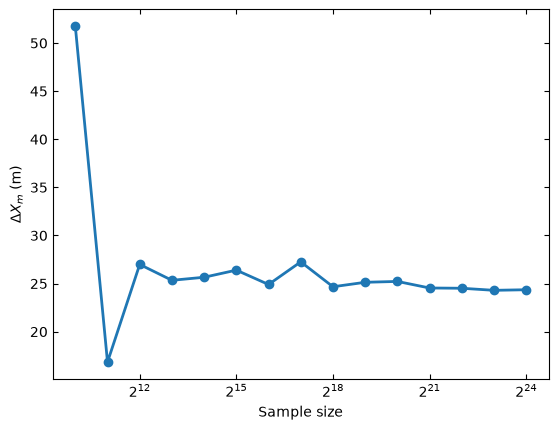

In [ ]:
f_source = 62 #Hz
c_light = 3e8
n_eff = 1.462
x_std_arr = []
sampling_time_arr = []

for i in range(10,25):
    sampling_time = 2**i
    complex40_122hz = hilbert(amp40_122hz[:sampling_time])
    complex80_122hz = hilbert(amp80_122hz[:sampling_time])
    phase_diff = np.unwrap(np.angle(complex40_122hz * np.conj(complex80_122hz)))
    x_measured = (phase_diff/(2 * np.pi * f_source * n_eff)) * c_light

    x_mean = np.mean(x_measured)
    x_std = np.std(x_measured)
    x_std_arr.append(x_std)
    sampling_time_arr.append(sampling_time)

plt.plot(sampling_time_arr, x_std_arr, 'o-', linewidth=2)
plt.xlabel('Sample size')
plt.ylabel(r'$\Delta X_m$ (m)')


plt.xscale('log', base=2)
#plt.yscale('log')
plt.xticks([2**i for i in range(12, 25, 3)])
#plt.yticks([10**2, 10**5, 10**8])

#plt.ylim(10**0, 10**8)
plt.tick_params(direction='in', which='major', top=True, right=True)
plt.tick_params(which='minor', bottom=False, left=False, top=False, right=False)

plt.show()
